## Classification in Python with PyTorch

In this section, we implement a classification model using PyTorch, a deep learning framework for building and training neural networks. We use a Multi-Layer Perceptron (MLP) to classify data points into different classes based on their input features.

The implementation covers neural network construction, forward propagation, loss computation, backpropagation, and parameter optimization. We also investigate how network depth affects classification accuracy, model complexity, and training time.

## Classification in Python with PyTorch

In this section, we implement a Multi-Layer Perceptron (MLP) using PyTorch to classify non-linearly separable data. We study how neural networks learn decision boundaries and how different architectural and training parameters affect classification performance.

### Objectives

- Understand the classification problem and MLP architecture.
- Implement forward propagation, loss computation, and gradient descent.
- Visualize how the decision boundary evolves during training.
- Investigate the effects of network depth, width, activation functions, learning rate, data noise, and training set size on classification accuracy.
- Compare model complexity, computational cost, and predictive performance.

**Class 0:**

$$
\mathbf{x}_0 =
\begin{pmatrix}
\cos t \\
\sin t
\end{pmatrix}
+ \boldsymbol{\varepsilon}
$$

**Class 1:**

$$
\mathbf{x}_1 =
\begin{pmatrix}
1-\cos t \\
2-\sin t
\end{pmatrix}
+ \boldsymbol{\varepsilon}
$$

where

$$
\boldsymbol{\varepsilon} \sim \mathcal{N}(\mathbf{0}, \sigma^2 I).
$$

For each class, the parameter `t` is equally spaced in the interval `[0, π]`. Class 0 contains `floor(n/2)` points, while class 1 contains the remaining points. The generated points are then shuffled.

Class 0 represents the upper moon, and class 1 represents the lower moon. The tips of each moon extend into the opening of the other moon.

The parameter `σ` controls the noise level. For large values of `σ`, the two classes increasingly overlap, making classification more difficult.

In [5]:
%pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-macosx_12_0_arm64.whl (8.3 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl (20.5 MB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [27]:

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import torch
import torch.nn as nn
import os
import matplotlib.pyplot as plt
import numpy as np



In [19]:



def make_data(
    n_samples=800,
    noise=0.18,
    seed=3,
    test_size=0.25,
    split_seed=1
):
    # 1. Generate the two-moons dataset
    X, y = make_moons(
        n_samples=n_samples,
        noise=noise,
        random_state=seed
    )

    # 2. Split into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=split_seed
    )

    # 3. Standardize the features
    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # 4. Convert NumPy arrays into PyTorch tensors
    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.long)

    X_test = torch.tensor(X_test, dtype=torch.float32)
    y_test = torch.tensor(y_test, dtype=torch.long)

    return X_train, y_train, X_test, y_test

In [21]:
X_train, y_train, X_test, y_test = make_data()

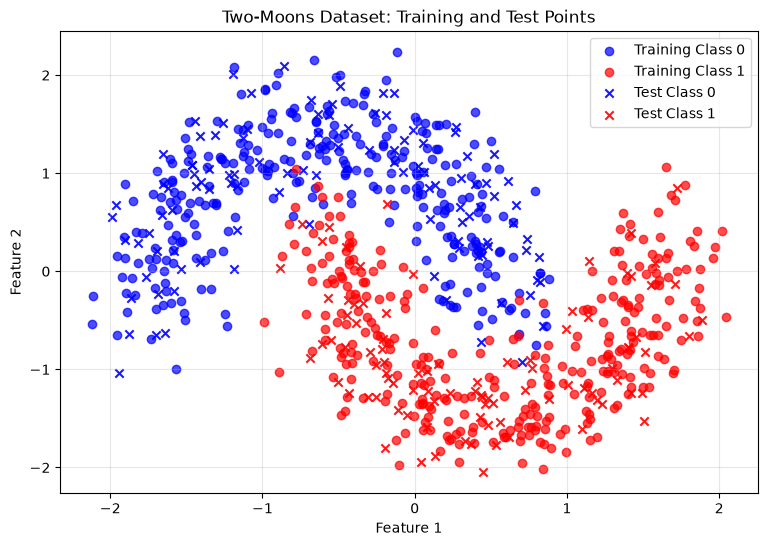

In [22]:
# Convert PyTorch tensors to NumPy arrays for plotting
X_train_np = X_train.numpy()
y_train_np = y_train.numpy()

X_test_np = X_test.numpy()
y_test_np = y_test.numpy()

# Create the figure
plt.figure(figsize=(9, 6))

# Plot training points
for class_id, color in zip([0, 1], ["blue", "red"]):

    mask = y_train_np == class_id

    plt.scatter(
        X_train_np[mask, 0],
        X_train_np[mask, 1],
        color=color,
        marker="o",
        label=f"Training Class {class_id}",
        alpha=0.7
    )

# Plot test points
for class_id, color in zip([0, 1], ["blue", "red"]):

    mask = y_test_np == class_id

    plt.scatter(
        X_test_np[mask, 0],
        X_test_np[mask, 1],
        color=color,
        marker="x",
        label=f"Test Class {class_id}",
        alpha=0.9
    )

# Add labels and title
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Two-Moons Dataset: Training and Test Points")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [24]:



class MLP(nn.Module):
    """
    Fully connected network with depth hidden layers.

    Every hidden layer has width neurons.
    For depth = 0, the model is a single linear layer.
    The outputs are logits (no softmax).
    """

    def __init__(
        self,
        input_dim=2,
        output_dim=2,
        width=32,
        depth=2,
        activation=nn.ReLU
    ):
        super().__init__()

        # Store all layers in a list
        layers = []

        # Build hidden layers
        for i in range(depth):

            # First hidden layer receives input_dim features.
            # Remaining hidden layers receive width features.
            in_features = input_dim if i == 0 else width

            layers.append(nn.Linear(in_features, width))
            layers.append(activation())

        # Final output layer
        if depth > 0:
            layers.append(nn.Linear(width, output_dim))
        else:
            layers.append(nn.Linear(input_dim, output_dim))

        # Combine all layers into one sequential network
        self.network = nn.Sequential(*layers)

    def forward(self, x):

        return self.network(x)

In [25]:
model = MLP(
    input_dim=2,
    output_dim=2,
    width=32,
    depth=2,
    activation=nn.ReLU
)

print(model)

MLP(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)


In [28]:



def plot_decision_boundary(
    model,
    X,
    y,
    epoch,
    loss,
    acc,
    outdir="nn_two_moons_frames",
    show_live=False,
    grid_resolution=300
):
    model.eval()

    # Create a grid covering the data points
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, grid_resolution),
        np.linspace(y_min, y_max, grid_resolution)
    )

    # Convert grid points into a PyTorch tensor
    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_t = torch.tensor(grid, dtype=torch.float32)

    # Predict class probabilities
    with torch.no_grad():
        logits = model(grid_t)
        probs = torch.softmax(logits, dim=1)[:, 1].numpy()

    zz = probs.reshape(xx.shape)

    # Plot decision boundary
    plt.figure(figsize=(6, 5))

    # Background: probability of class 1
    plt.contourf(xx, yy, zz, levels=50, alpha=0.8)

    # Decision boundary: probability = 0.5
    plt.contour(xx, yy, zz, levels=[0.5], linewidths=2)

    # Plot data points
    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        s=25,
        edgecolor="k"
    )

    plt.title(
        f"Epoch {epoch} | Loss = {loss:.4f} | Test accuracy = {acc:.3f}"
    )

    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")

    plt.tight_layout()

    # Save the figure
    os.makedirs(outdir, exist_ok=True)

    filename = os.path.join(
        outdir,
        f"decision_boundary_{epoch:04d}.png"
    )

    plt.savefig(filename, dpi=150)

    if show_live:
        plt.pause(0.05)

    plt.close()

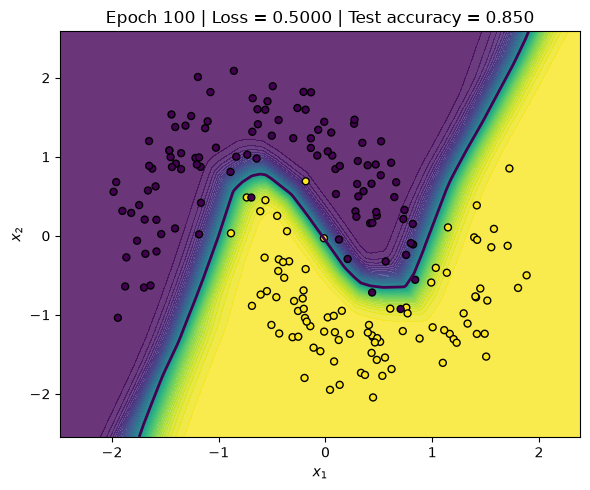

In [40]:
plot_decision_boundary(
    model=model,
    X=X_test.numpy(),
    y=y_test.numpy(),
    epoch=100,
    loss=0.5,
    acc=0.85,
    show_live=True
)

In [31]:
output = model(X_train)

print("Input shape:", X_train.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([600, 2])
Output shape: torch.Size([600, 2])


In [32]:
def plot_decision_boundary(
    model,
    X,
    y,
    epoch,
    loss,
    acc,
    outdir="nn_two_moons_frames",
    show_live=False,
    grid_resolution=300
):

    model.eval()

    # Define plotting limits
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    # Create a coordinate grid
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, grid_resolution),
        np.linspace(y_min, y_max, grid_resolution)
    )

    # Convert grid points into a PyTorch tensor
    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_t = torch.tensor(grid, dtype=torch.float32)

    # Calculate class probabilities
    with torch.no_grad():

        logits = model(grid_t)

        probs = torch.softmax(logits, dim=1)[:, 1].numpy()

    zz = probs.reshape(xx.shape)

    # Plot decision boundary
    plt.figure(figsize=(6, 5))

    plt.contourf(xx, yy, zz, levels=50, alpha=0.8)
    plt.contour(xx, yy, zz, levels=[0.5], linewidths=2)

    plt.scatter(
        X[:, 0],
        X[:, 1],
        c=y,
        s=25,
        edgecolor="k"
    )

    plt.title(
        f"Epoch {epoch} | Loss = {loss:.4f} | Test accuracy = {acc:.3f}"
    )

    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$")

    plt.tight_layout()

    # Create output folder
    os.makedirs(outdir, exist_ok=True)

    # Save figure
    filename = os.path.join(
        outdir,
        f"decision_boundary_{epoch:04d}.png"
    )

    plt.savefig(filename, dpi=150)

    if show_live:
        plt.show()

    plt.close()

In [30]:
# ============================================================
# 3. Accuracy function
# ============================================================

@torch.no_grad()
def accuracy(model, X, y):
    """Fraction of correctly classified points."""

    model.eval()

    logits = model(X)
    predictions = torch.argmax(logits, dim=1)

    correct = (predictions == y).sum()

    return (correct / len(y)).item()

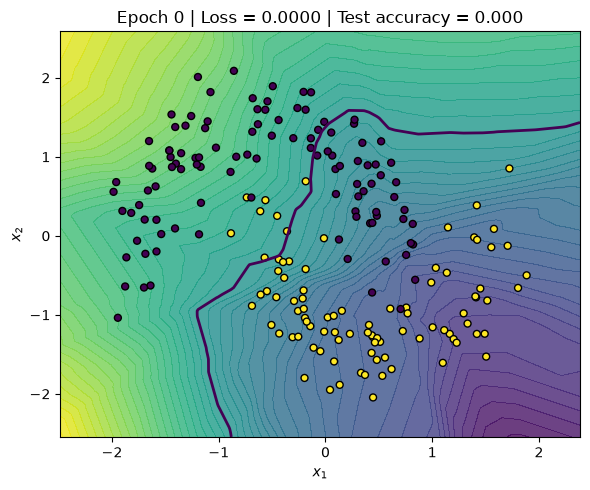

In [33]:
X_plot = X_test.detach().cpu().numpy()
y_plot = y_test.detach().cpu().numpy()

plot_decision_boundary(
    model,
    X_plot,
    y_plot,
    epoch=0,
    loss=0.0,
    acc=0.0,
    show_live=True
)

In [41]:
#===========================================================================
# Test accuracy 
#=========================================================================== 
@torch.no_grad()
def accuracy(model, X, y):

    """
    Calculate the fraction of correctly classified points.
    """

    model.eval()

    # Calculate logits
    logits = model(X)

    # Select the class with the largest logit
    predictions = torch.argmax(logits, dim=1)

    # Count correct predictions
    correct = (predictions == y).sum()

    # Calculate accuracy
    return (correct / len(y)).item()

In [35]:
train_acc = accuracy(model, X_train, y_train)
test_acc = accuracy(model, X_test, y_test)

print("Training accuracy:", train_acc)
print("Test accuracy:", test_acc)

Training accuracy: 0.21833333373069763
Test accuracy: 0.23999999463558197


In [ ]:
#===========================================================
#Train the neural network
#===========================================================

def train_model(
    model,
    X_train,
    y_train,
    X_test,
    y_test,
    X_plot,
    y_plot,
    epochs=10000,
    lr=1e-2,
    plot_every=50,
    outdir="nn_two_moons_frames"
):

    """
    Full-batch gradient descent with cross-entropy loss.

    Returns a dictionary containing:
    - loss
    - train_acc
    - test_acc
    """

    # Define loss function
    loss_fn = nn.CrossEntropyLoss()

    # Define optimizer
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr=lr
    )

    # Store training history
    hist = {
        "loss": [],
        "train_acc": [],
        "test_acc": []
    }

    # ------------------------------------------------
    # Initial evaluation (epoch 0)
    # ------------------------------------------------

    model.eval()

    with torch.no_grad():

        initial_logits = model(X_train)

        initial_loss = loss_fn(
            initial_logits,
            y_train
        ).item()

    initial_train_acc = accuracy(model, X_train, y_train)
    initial_test_acc = accuracy(model, X_test, y_test)

    hist["loss"].append(initial_loss)
    hist["train_acc"].append(initial_train_acc)
    hist["test_acc"].append(initial_test_acc)

    # Plot initial decision boundary
    plot_decision_boundary(
        model,
        X_plot,
        y_plot,
        epoch=0,
        loss=initial_loss,
        acc=initial_test_acc,
        outdir=outdir
    )

    # ------------------------------------------------
    # Training loop
    # ------------------------------------------------

    for epoch in range(1, epochs + 1):

        model.train()

        # Forward pass
        logits = model(X_train)

        # Calculate loss
        loss = loss_fn(logits, y_train)

        # Backpropagation
        optimizer.zero_grad()

        loss.backward()

        # Update model parameters
        optimizer.step()

        # Calculate accuracy
        train_acc = accuracy(model, X_train, y_train)
        test_acc = accuracy(model, X_test, y_test)

        # Store results
        hist["loss"].append(loss.item())
        hist["train_acc"].append(train_acc)
        hist["test_acc"].append(test_acc)

        # Print and plot at specified intervals
        if epoch % plot_every == 0:

            print(
                f"Epoch {epoch:5d} | "
                f"Loss = {loss.item():.4f} | "
                f"Train accuracy = {train_acc:.3f} | "
                f"Test accuracy = {test_acc:.3f}"
            )

            plot_decision_boundary(
                model,
                X_plot,
                y_plot,
                epoch=epoch,
                loss=loss.item(),
                acc=test_acc,
                outdir=outdir
            )

    return hist

In [42]:
#Create a fresh model
model = MLP(
    input_dim=2,
    output_dim=2,
    width=32,
    depth=2,
    activation=nn.ReLU
)

In [ ]:
#Start training
history = train_model(
    model,
    X_train,
    y_train,
    X_test,
    y_test,
    X_plot,
    y_plot,
    epochs=10000,
    lr=0.01,
    plot_every=50
)

Epoch    50 | Loss = 0.6435 | Train accuracy = 0.610 | Test accuracy = 0.565
Epoch   100 | Loss = 0.5423 | Train accuracy = 0.877 | Test accuracy = 0.875
Epoch   150 | Loss = 0.4464 | Train accuracy = 0.868 | Test accuracy = 0.880
Epoch   200 | Loss = 0.3762 | Train accuracy = 0.870 | Test accuracy = 0.880
Epoch   250 | Loss = 0.3353 | Train accuracy = 0.867 | Test accuracy = 0.885
Epoch   300 | Loss = 0.3134 | Train accuracy = 0.865 | Test accuracy = 0.890
Epoch   350 | Loss = 0.3016 | Train accuracy = 0.868 | Test accuracy = 0.890
Epoch   400 | Loss = 0.2948 | Train accuracy = 0.872 | Test accuracy = 0.890
Epoch   450 | Loss = 0.2905 | Train accuracy = 0.872 | Test accuracy = 0.895
Epoch   500 | Loss = 0.2876 | Train accuracy = 0.873 | Test accuracy = 0.895
Epoch   550 | Loss = 0.2853 | Train accuracy = 0.872 | Test accuracy = 0.890
Epoch   600 | Loss = 0.2835 | Train accuracy = 0.875 | Test accuracy = 0.890
Epoch   650 | Loss = 0.2820 | Train accuracy = 0.877 | Test accuracy = 0.890

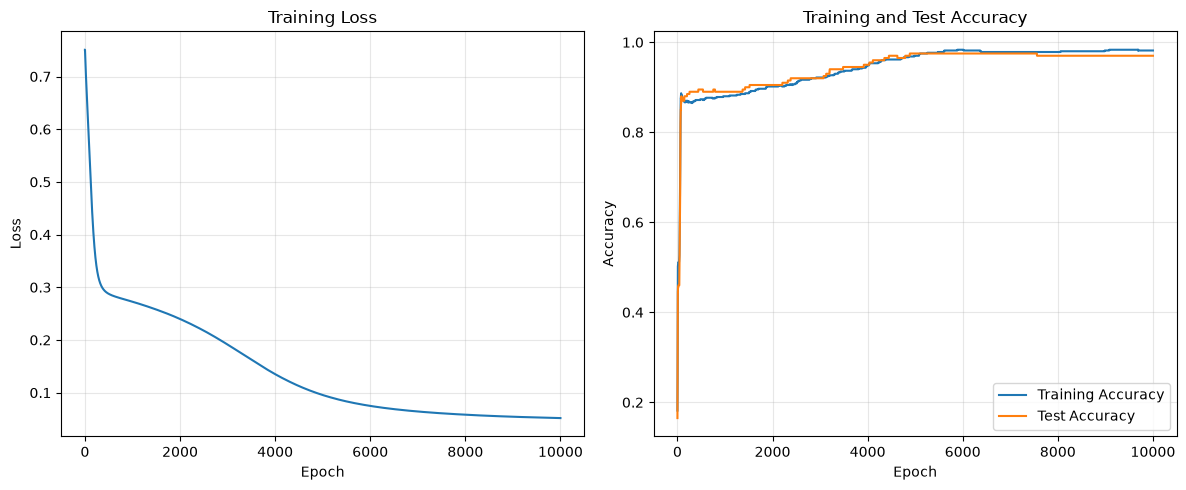

In [43]:
#Plot training loss and accuracy
epochs_range = range(len(history["loss"]))

plt.figure(figsize=(12, 5))

# Plot training loss
plt.subplot(1, 2, 1)

plt.plot(epochs_range, history["loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.grid(alpha=0.3)


# Plot training and test accuracy
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history["test_acc"],
    label="Test Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Test Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()